In [24]:
#Sesion 4: Preparacion de datos

#Producto final: Limpieza, codificacion y particion de datos.
#Entender por que los datos crudos casi nunca se pueden utilizar usar directamente en un modelo.
#Tratar valores nulos con criterios justificados.
#Eliminar columnas que no aportan algun valor preduiictivo.
#Codificar variables categoricas a formato numerico.
#Crear variables nuevas simples y utiles.
#Escalar variables numericas.
# Dividir el dataset en conjuntos de entrenamiento y pruebas.


#Esta sesion es el puente entre EDA y los modelos de Machine Learning.

In [25]:
pip install scikit-learn


^C
Note: you may need to restart the kernel to use updated packages.


Defaulting to user installation because normal site-packages is not writeable


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder


sns.set_theme(style="whitegrid")



In [ ]:
df =pd.read_csv("titanic.csv")

print("Filas y columnas originales:", df.shape)
df.head()
      

Filas y columnas originales: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
#¿POR QUE PREPARA LOS DATOS?
#Un modelo de machine Learning solo entiende numeros, Ademas es sensible a:
#Valores faltantes(NAN) -> muchos algoritmos simplemente fallan sin los encuentran.
#Texto sin convertir ("Male", "Female", "S", "C", "Q") -> deben transformarse a numeros.
#Columnas irrelevantes(como un nombre o numero de boleto) --> puede condunfir el modelo o no aportar nada.
#Escalas muy distintas entre columnas(por ejemplo: Age entre 0-80 y Fare entre 0-500) --> puede afectar el rendimiento del modelo.
#

In [ ]:
df.isnull().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

In [ ]:
#Copiamos el dataframe original para no perderlo y trabajar sobre la copia.
df_prep = df.copy()

#Cabin: se elimina mas adelante junto con otras columnas irrelevantes.
#Age: imputacion con la mediana.

mediana_edad = df_prep["Age"].median()
df_prep["Age"] = df_prep["Age"].fillna(mediana_edad)
print("Mediana de edad usada para imputar:", mediana_edad)

#embarked: se imputa con la moda.
moda_embarque = df_prep["Embarked"].mode()[0]
df_prep["Embarked"] = df_prep["Embarked"].fillna(moda_embarque)
print("Moda de embarque usada para imputar:", moda_embarque)

print()
print("Valores nulos despues de la imputacion:")
print(df_prep.isnull().sum().sort_values(ascending=False))


Mediana de edad usada para imputar: 28.0
Moda de embarque usada para imputar: S

Valores nulos despues de la imputacion:
Cabin          687
PassengerId      0
Pclass           0
Survived         0
Name             0
Sex              0
SibSp            0
Age              0
Parch            0
Ticket           0
Fare             0
Embarked         0
dtype: int64


In [ ]:
columnas_a_eliminar = ["PassengerId", "Name", "Ticket", "Cabin"]
df_prep = df_prep.drop(columns=columnas_a_eliminar, errors='ignore')
#Metodo para eliminar es drop()
print("Columnas restantes:", df_prep.columns.tolist())
df_prep.head()

Columnas restantes: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone
0,0,3,male,22.0,1,0,7.2500,S,2,0
1,1,1,female,38.0,1,0,71.2833,C,2,0
2,1,3,female,26.0,0,0,7.9250,S,1,1
3,1,1,female,35.0,1,0,53.1000,S,2,0
4,0,3,male,35.0,0,0,8.0500,S,1,1


In [ ]:
#INGENIERIA CARACTERISTICAS SIMPLES

#PODEMOS CREAR NUEVAS COLUMNAS APARTIR DE LAS EXISTENTES PARA CAPTURAR INFORMACION UTIL QUE NO ESTE EXPLICITA.

#Tamaño total de la familia a bordo
df_prep["FamilySize"] = df_prep["SibSp"] + df_prep["Parch"] + 1
#Si viaja solo o no
df_prep["IsAlone"] = (df_prep["FamilySize"] == 1).astype(int)
df_prep[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


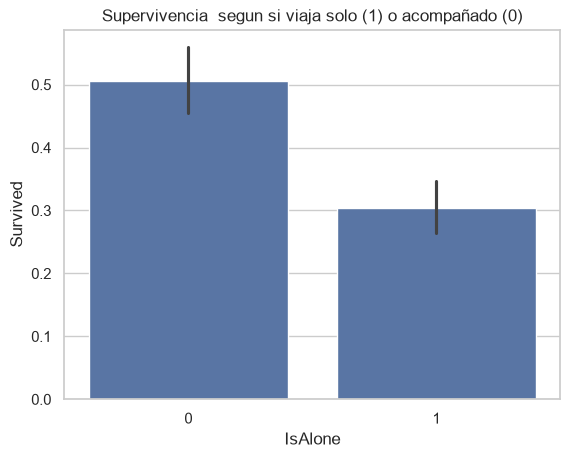

In [ ]:
sns.barplot(data=df_prep, x="IsAlone", y="Survived")
plt.title("Supervivencia  segun si viaja solo (1) o acompañado (0)")
plt.show()

In [ ]:
df_prep["Sex"] = df_prep["Sex"].map({"male": 0, "female": 1})
df_prep[["Sex"]].head()



#INVESTIGAR COMO FUNCION ONE-HOT ENCODING.

,Sex
0,0
1,1
2,1
3,1
4,0


In [ ]:
#ONE-HOT ENCODING
#Cuando una variable categorica tiene mas de dos categorias sin un orden natural(S,C,Q), la tecnica recomendada

#El One-Hot Encoding (codificación binaria o de uno en caliente) es un método para transformar variables categóricas (texto o etiquetas sin orden numérico) en columnas de números binarios (0 y 1) que los modelos de inteligencia artificial y machine learning pueden entender.
#¿Cómo funciona?Crea una columna nueva por cada valor único (categoría) que tenga la variable original.Asigna un valor de 1 en la columna correspondiente a la categoría activa y un 0 en todas las demás columnas de esa fila.


df_prep = pd.get_dummies(df_prep, columns=["Embarked"], prefix="Embarked", drop_first=True)
df_prep.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,2,0,False,True
1,1,1,1,38.0,1,0,71.2833,2,0,False,False
2,1,3,1,26.0,0,0,7.9250,1,1,False,True
3,1,1,1,35.0,1,0,53.1000,2,0,False,True
4,0,3,0,35.0,0,0,8.0500,1,1,False,True


In [ ]:
columnas_numericas = ["Age", "Fare","FamilySize"]

scaler = StandardScaler()
df_prep[columnas_numericas] = scaler.fit_transform(df_prep[columnas_numericas])

df_prep[columnas_numericas].describe().round(2)



,Age,Fare,FamilySize
count,891.00,891.00,891.00
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.22,-0.65,-0.56
25%,-0.57,-0.49,-0.56
50%,-0.10,-0.36,-0.56
75%,0.43,-0.02,0.06
max,3.89,9.67,5.64


In [ ]:
df_prep

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked_Q,Embarked_S
0,0,3,0,-0.565736,1,0,-0.502445,0.059160,0,False,True
1,1,1,1,0.663861,1,0,0.786845,0.059160,0,False,False
2,1,3,1,-0.258337,0,0,-0.488854,-0.560975,1,False,True
3,1,1,1,0.433312,1,0,0.420730,0.059160,0,False,True
4,0,3,0,0.433312,0,0,-0.486337,-0.560975,1,False,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,-0.181487,0,0,-0.386671,-0.560975,1,False,True
887,1,1,1,-0.796286,0,0,-0.044381,-0.560975,1,False,True
888,0,3,1,-0.104637,1,2,-0.176263,1.299429,0,False,True
889,1,1,0,-0.258337,0,0,-0.044381,-0.560975,1,False,False


In [28]:
#Division en Conjuntos de entrenamiento y prueba
#Antes de entrenar cualquier modelo, debemos separar los datos en 2 secciones:
#Conjunto de entrenamiento(Train): el modelo aprende con estos datos.
#Conjunto de prueba(Test): se usa solo al final para evaluar el rendimiento del modelo y ver si generaliza bien a datos nuevos.

#Usaremos un 80 / 20% de forma estratificada.

x = df_prep.drop(columns=["Survived"])  #Variables predictorias
y = df_prep["Survived"]                 #Variable objetivo

x_train, x_test, y_train, y_test = train_test_split(
    x, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
    )

print("Tamaño de x_train:", x_train.shape)
print("Tamaño de x_test:", x_test.shape)
print()
print("Proporcion de sobrevivientes en y_train", y_train.mean().round(3))
print("Proporcion de sobrevivientes en y_test", y_test.mean().round(3))

Tamaño de x_train: (712, 10)
Tamaño de x_test: (179, 10)

Proporcion de sobrevivientes en y_train 0.383
Proporcion de sobrevivientes en y_test 0.385


In [29]:
#GUARDAR LOS DATOS PREPARADOS
x_train.to_csv("x_train.csv", index=False)
x_test.to_csv("x_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Archivos Guardados: x_train.csv, x_test.csv, y_train.csv, y_test.csv")




Archivos Guardados: x_train.csv, x_test.csv, y_train.csv, y_test.csv


In [37]:
#Reto Final: Funcion de preprocesamiento encapsulda.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


df =pd.read_csv("titanic.csv")

print("Filas y columnas originales:", df.shape)
df.head()
def  preparar_datos(df_original):
    df_local = df_original.copy()

    df.isnull().sum().sort_values(ascending=False)

    #1.IMPUTAR VALORES NULOS

    mediana_edad = df_prep["Age"].median()
    df_prep["Age"] = df_prep["Age"].fillna(mediana_edad)
    print("Mediana de edad usada para imputar:", mediana_edad)

    #embarked: se imputa con la moda.
    moda_embarque = df_prep["Embarked"].mode()[0]
    df_prep["Embarked"] = df_prep["Embarked"].fillna(moda_embarque)
    print("Moda de embarque usada para imputar:", moda_embarque)

    print()
    print("Valores nulos despues de la imputacion:")
    print(df_prep.isnull().sum().sort_values(ascending=False))

    #2.ELIMINAR COLUMNAS IRRELEVANTES
    columnas_a_eliminar = ["PassengerId", "Name", "Ticket", "Cabin"]
    df_prep = df_prep.drop(columns=columnas_a_eliminar, errors='ignore')
    #Metodo para eliminar es drop()
    print("Columnas restantes:", df_prep.columns.tolist())
    df_prep.head()

    #3.CREAR FAMILIA SIZE Y IS ALONE

    df_prep["FamilySize"] = df_prep["SibSp"] + df_prep["Parch"] + 1
    #Si viaja solo o no
    df_prep["IsAlone"] = (df_prep["FamilySize"] == 1).astype(int)
    df_prep[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

    sns.barplot(data=df_prep, x="IsAlone", y="Survived")
    plt.title("Supervivencia  segun si viaja solo (1) o acompañado (0)")
    plt.show()

    #4.CODIFICAR SEX Y EMBARKED
    df_prep["Sex"] = df_prep["Sex"].map({"male": 0, "female": 1})
    df_prep[["Sex"]].head()

    df_prep = pd.get_dummies(df_prep, columns=["Embarked"], prefix="Embarked", drop_first=True)
    df_prep.head()

    #5.ESCALAR AGE, FARE Y FAMILIZISE

    columnas_numericas = ["Age", "Fare","FamilySize"]

    scaler = StandardScaler()
    df_prep[columnas_numericas] = scaler.fit_transform(df_prep[columnas_numericas])

    df_prep[columnas_numericas].describe().round(2)

    #6.SEPARAR X E Y, Y DIVIDIR EN TRAIN/TEST
    x = df_prep.drop(columns=["Survived"])  #Variables predictorias
    y = df_prep["Survived"]                 #Variable objetivo

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, 
        test_size=0.2, 
        random_state=42, 
        stratify=y
    )

    print("Tamaño de x_train:", x_train.shape)
    print("Tamaño de x_test:", x_test.shape)
    print()
    print("Proporcion de sobrevivientes en y_train", y_train.mean().round(3))
    print("Proporcion de sobrevivientes en y_test", y_test.mean().round(3))

    return x_train, x_test, y_train, y_test


#GUARDAR LOS DATOS PREPARADOS
x_train.to_csv("x_train.csv", index=False)
x_test.to_csv("x_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Archivos Guardados: x_train.csv, x_test.csv, y_train.csv, y_test.csv")



   

Filas y columnas originales: (891, 12)
Archivos Guardados: x_train.csv, x_test.csv, y_train.csv, y_test.csv
